<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# Biểu đồ vùng (Area Plots), Histogram và Biểu đồ cột (Bar Plots)


Thời gian ước tính cần thiết: **30** phút
    

## Mục tiêu

Sau khi hoàn thành bài thực hành này, bạn sẽ có thể:

* Tạo thêm các biểu đồ, cụ thể là biểu đồ vùng (area plots), histogram và biểu đồ cột (bar charts)

## Mục lục

<div class="alert alert-block alert-info" style="margin-top: 20px">

1. [Khám phá bộ dữ liệu với *pandas*](#0)<br>
2. [Tải xuống và chuẩn bị dữ liệu](#2)<br>
3. [Trực quan hóa dữ liệu bằng Matplotlib](#4) <br>
4. [Biểu đồ vùng (Area Plots)](#6) <br>
5. [Histogram](#8) <br>
6. [Biểu đồ cột (Bar Charts)](#10) <br>
</div>

# Khám phá bộ dữ liệu với *pandas* và Matplotlib<a id="0"></a>

Bộ công cụ: Khóa học phụ thuộc nhiều vào [**pandas**](http://pandas.pydata.org/) và [**Numpy**](http://www.numpy.org/) để xử lý (data wrangling), phân tích và trực quan hóa dữ liệu. Thư viện vẽ biểu đồ chính mà chúng ta tìm hiểu trong khóa học là [Matplotlib](http://matplotlib.org/).

Bộ dữ liệu: Nhập cư vào Canada từ năm 1980 đến 2013 - [International migration flows to and from selected countries - The 2015 revision](http://www.un.org/en/development/desa/population/migration/data/empirical2/migrationflows.shtml) từ trang web của Liên Hợp Quốc.

Bộ dữ liệu chứa dữ liệu hằng năm về các luồng người di cư quốc tế do các quốc gia đến ghi nhận. Dữ liệu thể hiện cả luồng nhập và luồng xuất theo nơi sinh, quốc tịch hoặc nơi cư trú trước đó / tiếp theo, đối với cả người nước ngoài và công dân. Trong bài học này, chúng ta sẽ tập trung vào dữ liệu nhập cư vào Canada.

# Tải xuống và chuẩn bị dữ liệu <a id="2"></a>

Việc đầu tiên chúng ta làm là cài đặt **openpyxl** (trước đây là **xlrd**), một module mà *pandas* cần để đọc các tệp Excel.

In [1]:
!pip3 install openpyxl==3.1.0

  Attempting uninstall: openpyxl
    Found existing installation: openpyxl 3.1.5
    Uninstalling openpyxl-3.1.5:
      Successfully uninstalled openpyxl-3.1.5


Import các module chính. Việc đầu tiên chúng ta làm là import hai module phân tích dữ liệu quan trọng: `pandas` và `numpy`.

In [2]:
import numpy as np  # useful for many scientific computing in Python
import pandas as pd # primary data structure library

Tải xuống bộ dữ liệu nhập cư Canada và đọc nó vào một dataframe của *pandas*.

In [3]:
df_can = pd.read_excel(
    'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.xlsx',
    sheet_name='Canada by Citizenship',
    skiprows=range(20),
    skipfooter=2)
print('Data downloaded and read into a dataframe!')

Data downloaded and read into a dataframe!


Hãy xem qua năm phần tử đầu tiên trong bộ dữ liệu của chúng ta.

In [4]:
df_can.head()

,Type,Coverage,OdName,AREA,AreaName,REG,RegName,DEV,DevName,1980,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
0,Immigrants,Foreigners,Afghanistan,935,Asia,5501,Southern Asia,902,Developing regions,16,...,2978,3436,3009,2652,2111,1746,1758,2203,2635,2004
1,Immigrants,Foreigners,Albania,908,Europe,925,Southern Europe,901,Developed regions,1,...,1450,1223,856,702,560,716,561,539,620,603
2,Immigrants,Foreigners,Algeria,903,Africa,912,Northern Africa,902,Developing regions,80,...,3616,3626,4807,3623,4005,5393,4752,4325,3774,4331
3,Immigrants,Foreigners,American Samoa,909,Oceania,957,Polynesia,902,Developing regions,0,...,0,0,1,0,0,0,0,0,0,0
4,Immigrants,Foreigners,Andorra,908,Europe,925,Southern Europe,901,Developed regions,0,...,0,0,1,1,0,0,0,0,1,1


Hãy tìm xem có bao nhiêu mục (entry) trong bộ dữ liệu của chúng ta.

In [5]:
# print the dimensions of the dataframe
print(df_can.shape)

(195, 43)


Làm sạch dữ liệu. Chúng ta sẽ thực hiện một số thay đổi đối với bộ dữ liệu gốc để việc tạo các hình ảnh trực quan dễ dàng hơn. Hãy tham khảo bài thực hành `Introduction to Matplotlib and Line Plots` để biết lý do và mô tả chi tiết về các thay đổi.

#### 1. Làm sạch bộ dữ liệu để loại bỏ các cột không có nhiều thông tin hữu ích cho việc trực quan hóa (ví dụ: Type, AREA, REG).

In [6]:
df_can.drop(['AREA', 'REG', 'DEV', 'Type', 'Coverage'], axis=1, inplace=True)

# let's view the first five elements and see how the dataframe was changed
df_can.head()

,OdName,AreaName,RegName,DevName,1980,1981,1982,1983,1984,1985,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,2978,3436,3009,2652,2111,1746,1758,2203,2635,2004
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1450,1223,856,702,560,716,561,539,620,603
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3616,3626,4807,3623,4005,5393,4752,4325,3774,4331
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,0,1,1,0,0,0,0,1,1


Hãy lưu ý rằng các cột Type, Coverage, AREA, REG và DEV đã bị loại bỏ khỏi dataframe.

#### 2. Đổi tên một số cột để chúng có ý nghĩa hơn.

In [7]:
df_can.rename(columns={'OdName':'Country', 'AreaName':'Continent','RegName':'Region'}, inplace=True)

# let's view the first five elements and see how the dataframe was changed
df_can.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,2978,3436,3009,2652,2111,1746,1758,2203,2635,2004
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1450,1223,856,702,560,716,561,539,620,603
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3616,3626,4807,3623,4005,5393,4752,4325,3774,4331
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,0,1,1,0,0,0,0,1,1


Hãy lưu ý rằng các tên cột giờ đây có ý nghĩa hơn nhiều, ngay cả đối với người ngoài.

#### 3. Để đảm bảo tính nhất quán, hãy đảm bảo rằng tất cả các nhãn cột đều có kiểu string.

In [8]:
# let's examine the types of the column labels
all(isinstance(column, str) for column in df_can.columns)

False

Hãy lưu ý rằng dòng code ở trên trả về *False* khi chúng ta kiểm tra xem tất cả các nhãn cột có thuộc kiểu **string** hay không. Vì vậy, hãy chuyển tất cả chúng sang kiểu **string**.

In [9]:
df_can.columns = list(map(str, df_can.columns))

# let's check the column labels types now
all(isinstance(column, str) for column in df_can.columns)

True

#### 4. Đặt tên quốc gia làm index - hữu ích để tra cứu nhanh các quốc gia bằng phương thức .loc.

In [10]:
df_can.set_index('Country', inplace=True)

# Let's view the first five elements and see how the dataframe was changed
df_can.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,2978,3436,3009,2652,2111,1746,1758,2203,2635,2004
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1450,1223,856,702,560,716,561,539,620,603
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3616,3626,4807,3623,4005,5393,4752,4325,3774,4331
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,0,1,1,0,0,0,0,1,1


Hãy lưu ý rằng giờ đây tên các quốc gia đóng vai trò là các index.

#### 5. Thêm cột tổng (total).

In [12]:
df_can['Total'] = df_can.loc[:,"1980":"2013"].sum(axis=1)

# let's view the first five elements and see how the dataframe was changed
df_can.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


Giờ đây dataframe có thêm một cột thể hiện tổng số người nhập cư từ mỗi quốc gia trong bộ dữ liệu từ năm 1980 - 2013. Vì vậy, nếu in số chiều của dữ liệu, chúng ta nhận được:

In [13]:
print('data dimensions:', df_can.shape)

data dimensions: (195, 38)


Như vậy, dataframe của chúng ta giờ có 38 cột thay vì 37 cột như trước.

In [14]:
# finally, let's create a list of years from 1980 - 2013
# this will come in handy when we start plotting the data
years = list(map(str, range(1980, 2014)))

years

['1980',
 '1981',
 '1982',
 '1983',
 '1984',
 '1985',
 '1986',
 '1987',
 '1988',
 '1989',
 '1990',
 '1991',
 '1992',
 '1993',
 '1994',
 '1995',
 '1996',
 '1997',
 '1998',
 '1999',
 '2000',
 '2001',
 '2002',
 '2003',
 '2004',
 '2005',
 '2006',
 '2007',
 '2008',
 '2009',
 '2010',
 '2011',
 '2012',
 '2013']

# Trực quan hóa dữ liệu bằng Matplotlib<a id="4"></a>

Import thư viện `matplotlib`.

In [15]:
# use the inline backend to generate the plots within the browser
%matplotlib inline

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.style.use('ggplot')  # optional: for ggplot-like style

# check for latest version of Matplotlib
print('Matplotlib version: ', mpl.__version__) # >= 2.0.0

Matplotlib version:  3.10.0


# Biểu đồ vùng (Area Plots)<a id="6"></a>

Trong module trước, chúng ta đã tạo một biểu đồ đường (line plot) trực quan hóa 5 quốc gia đóng góp nhiều người nhập cư nhất vào Canada từ năm 1980 đến 2013. Chỉ với một chút chỉnh sửa code, chúng ta có thể trực quan hóa biểu đồ này dưới dạng biểu đồ tích lũy, còn được gọi là **Stacked Line Plot** hoặc **Area plot**.

In [16]:
df_can.sort_values(['Total'], ascending=False, axis=0, inplace=True)

# get the top 5 entries
df_top5 = df_can.head()

# transpose the dataframe
df_top5 = df_top5[years].transpose()

df_top5.head()

Country,India,China,United Kingdom of Great Britain and Northern Ireland,Philippines,Pakistan
1980,8880,5123,22045,6051,978
1981,8670,6682,24796,5921,972
1982,8147,3308,20620,5249,1201
1983,7338,1863,10015,4562,900
1984,5704,1527,10170,3801,668


Các biểu đồ vùng (area plot) mặc định được xếp chồng (stacked). Để tạo một biểu đồ vùng xếp chồng, mỗi cột phải có tất cả giá trị dương hoặc tất cả giá trị âm (mọi giá trị `NaN`, tức là not a number, sẽ mặc định là 0). Để tạo biểu đồ không xếp chồng (unstacked), hãy đặt tham số `stacked` thành giá trị `False`.

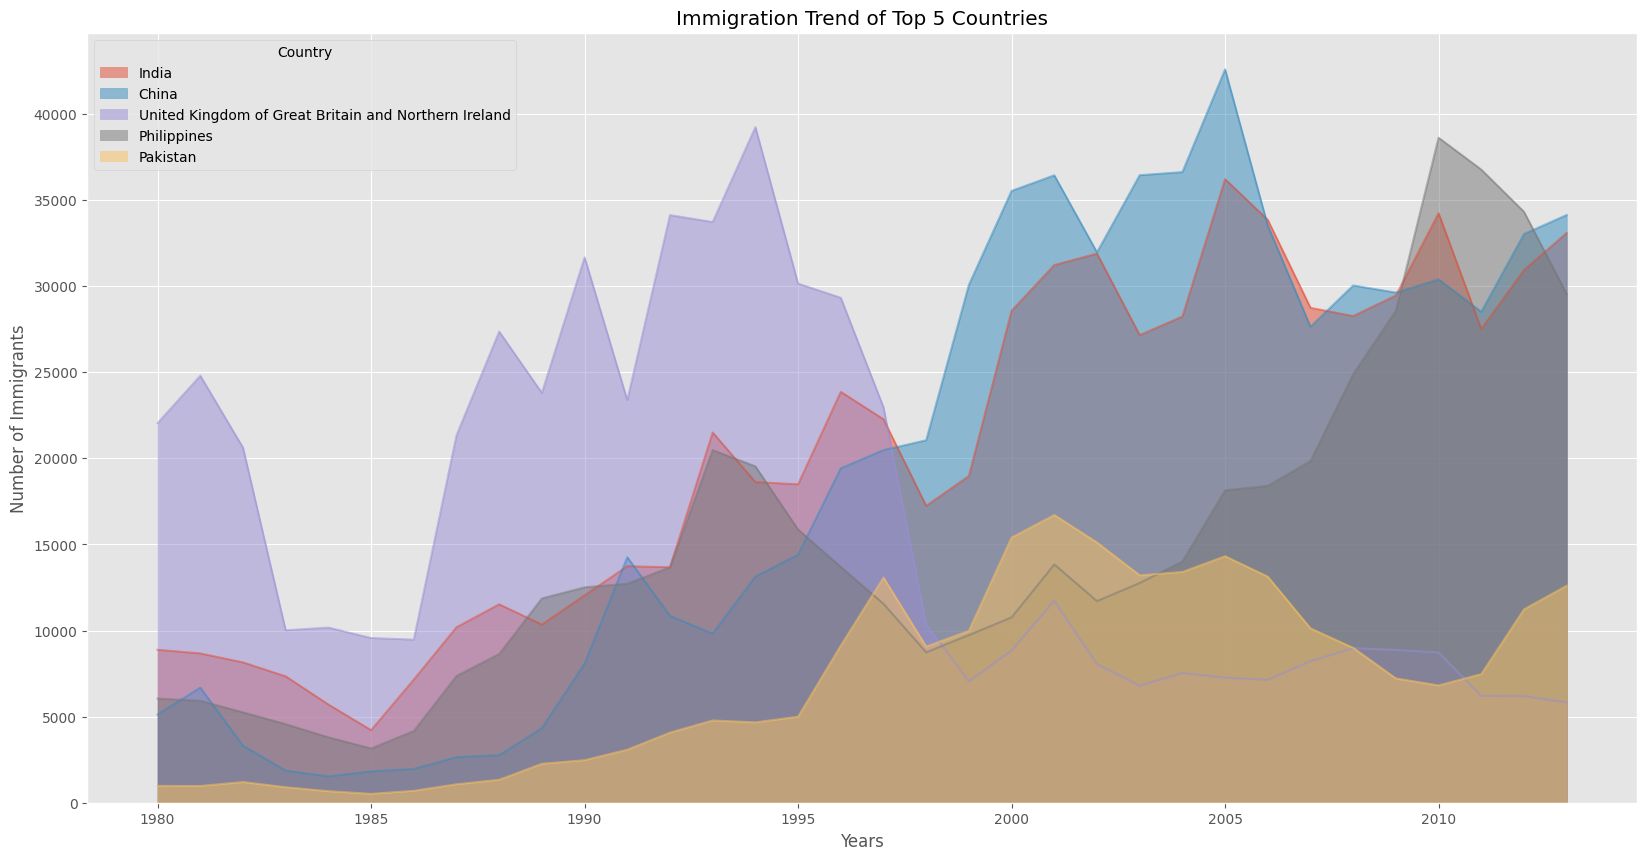

In [17]:
# let's change the index values of df_top5 to type integer for plotting
df_top5.index = df_top5.index.map(int)
df_top5.plot(kind='area',
             stacked=False,
             figsize=(20, 10))  # pass a tuple (x, y) size

plt.title('Immigration Trend of Top 5 Countries')
plt.ylabel('Number of Immigrants')
plt.xlabel('Years')

plt.show()

Biểu đồ không xếp chồng có độ trong suốt (giá trị alpha) mặc định là 0.5. Chúng ta có thể thay đổi giá trị này bằng cách truyền tham số `alpha`.

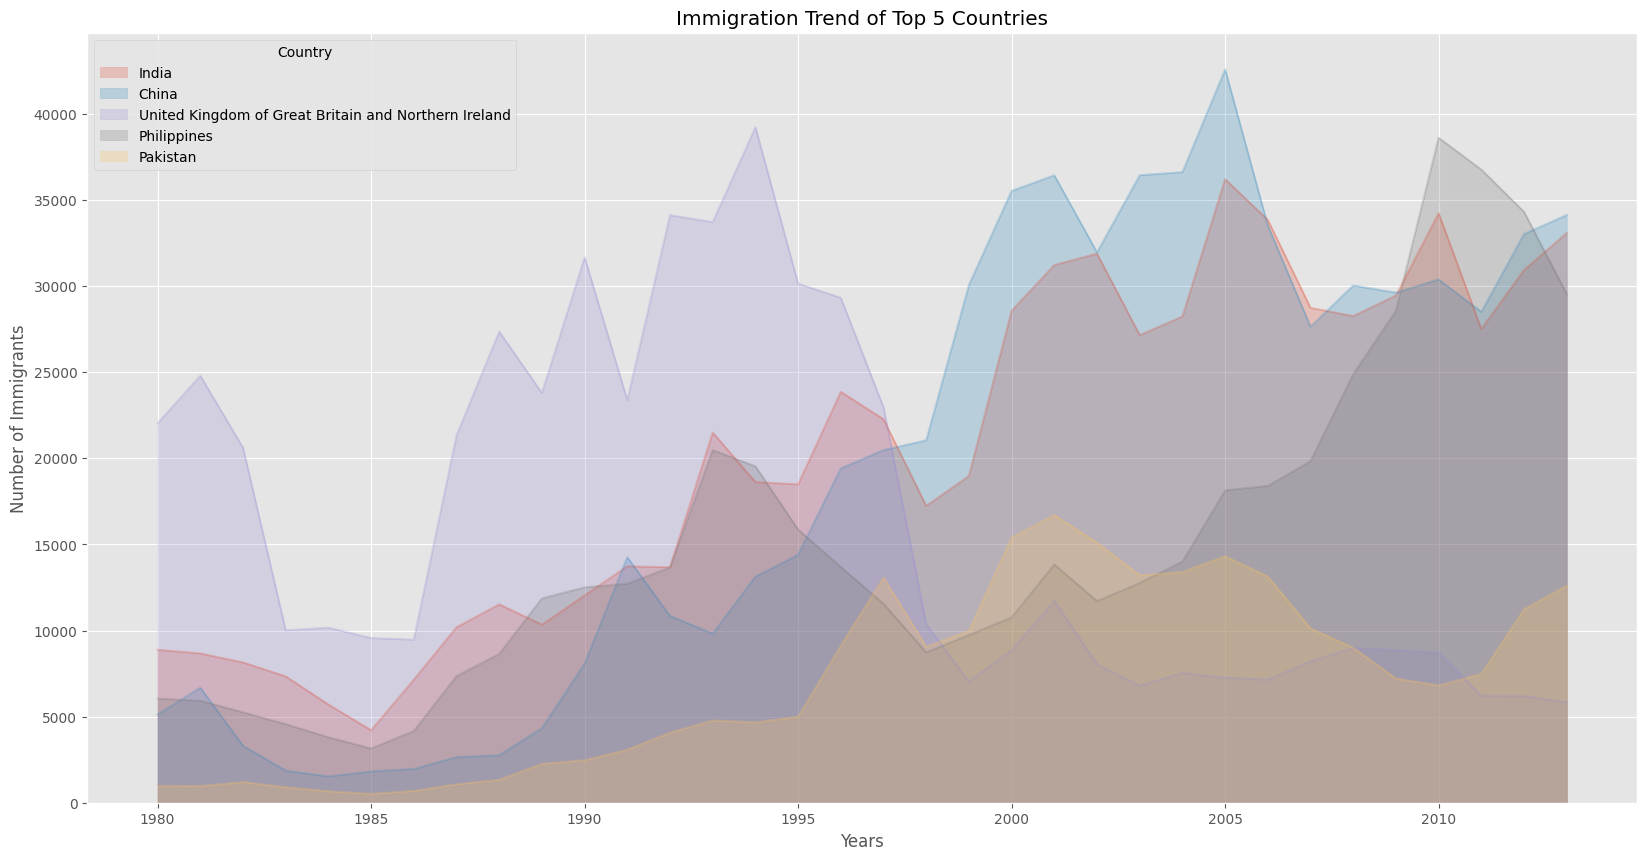

In [18]:
df_top5.plot(kind='area', 
             alpha=0.25,  # 0 - 1, default value alpha = 0.5
             stacked=False,
             figsize=(20, 10))

plt.title('Immigration Trend of Top 5 Countries')
plt.ylabel('Number of Immigrants')
plt.xlabel('Years')

plt.show()

### Hai kiểu vẽ biểu đồ

Như đã thảo luận trong các video bài giảng, có hai phong cách/lựa chọn vẽ biểu đồ với `matplotlib`, đó là vẽ bằng lớp Artist (Artist layer) và vẽ bằng lớp scripting (scripting layer).

**Lựa chọn 1: Lớp scripting (phương pháp thủ tục - procedural) - sử dụng matplotlib.pyplot với tên 'plt' **

Bạn có thể dùng `plt`, tức là `matplotlib.pyplot`, và thêm các thành phần bằng cách gọi các phương thức khác nhau theo kiểu thủ tục; ví dụ, `plt.title(...)` để thêm tiêu đề hoặc `plt.xlabel(...)` để thêm nhãn cho trục x.


Text(0.5, 0, 'Years')

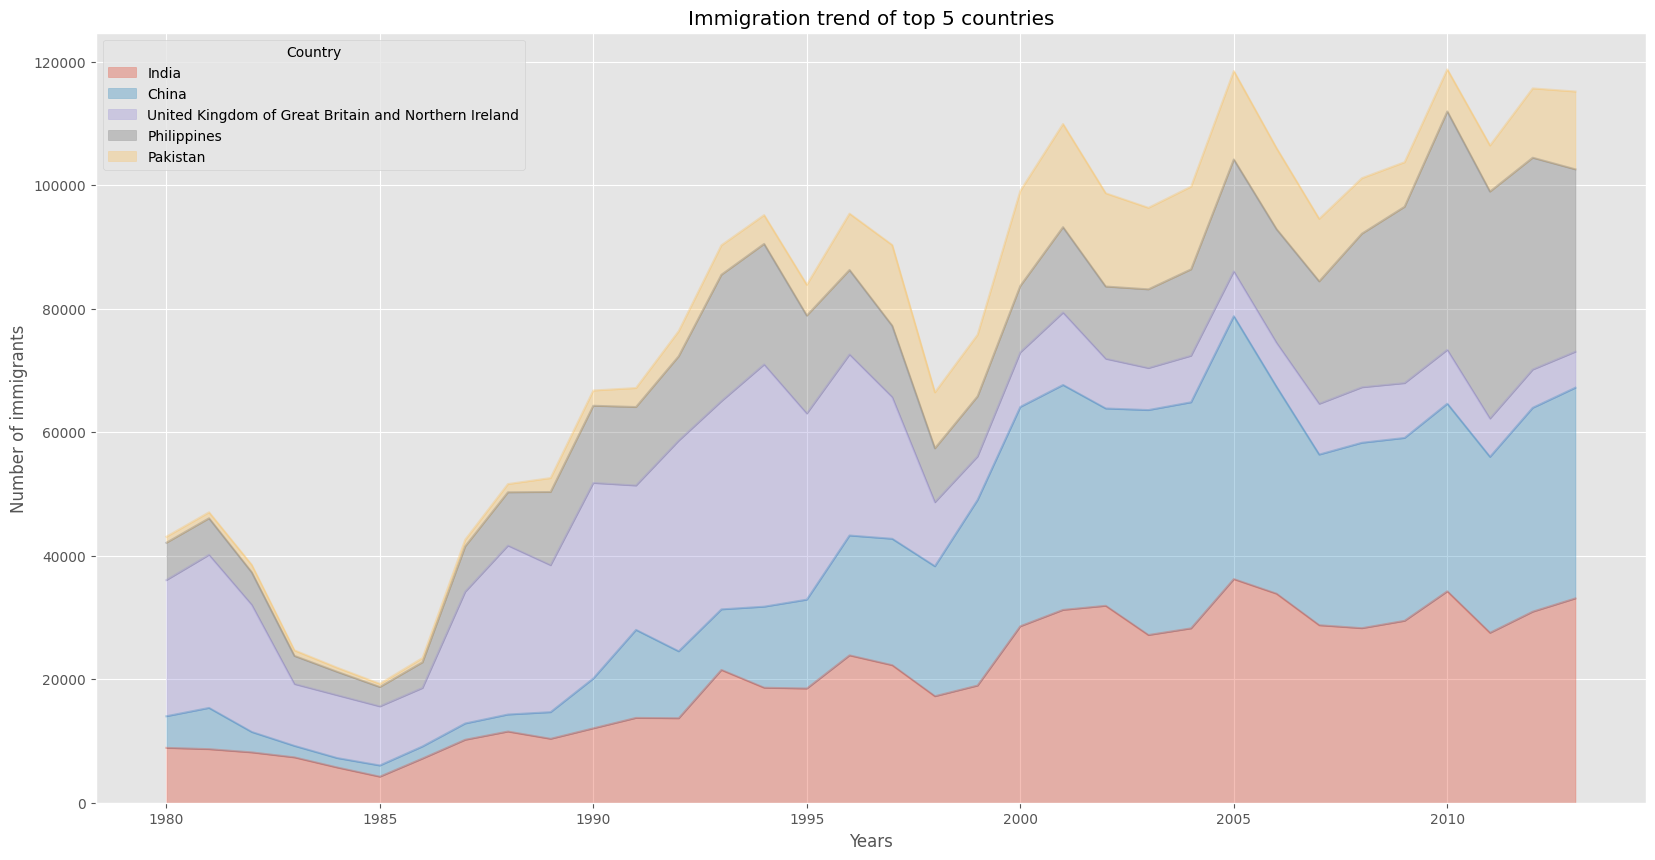

In [20]:
# Option 1: This is what we have been using so far
df_top5.plot(kind='area', alpha=0.35, figsize=(20, 10)) 
plt.title('Immigration trend of top 5 countries')
plt.ylabel('Number of immigrants')
plt.xlabel('Years')

**Lựa chọn 2: Lớp Artist (phương pháp hướng đối tượng - Object oriented) - sử dụng một instance `Axes` từ Matplotlib (được ưu tiên) **

Bạn có thể dùng một instance `Axes` của biểu đồ hiện tại và lưu nó vào một biến (ví dụ `ax`). Bạn có thể thêm các thành phần bằng cách gọi các phương thức với một chút thay đổi về cú pháp (bằng cách thêm "`set_`" vào các phương thức trước đó). Ví dụ, dùng `ax.set_title()` thay cho `plt.title()` để thêm tiêu đề, hoặc `ax.set_xlabel()` thay cho `plt.xlabel()` để thêm nhãn cho trục x.

Lựa chọn này đôi khi rõ ràng và linh hoạt hơn khi sử dụng cho các biểu đồ nâng cao (đặc biệt khi có nhiều biểu đồ, như bạn sẽ thấy sau này). 

Trong khóa học này, chúng ta sẽ dùng **lớp scripting**, ngoại trừ một số hình ảnh trực quan nâng cao mà chúng ta cần dùng **lớp artist** để điều khiển các khía cạnh nâng cao của biểu đồ.

Text(0.5, 0, 'Years')

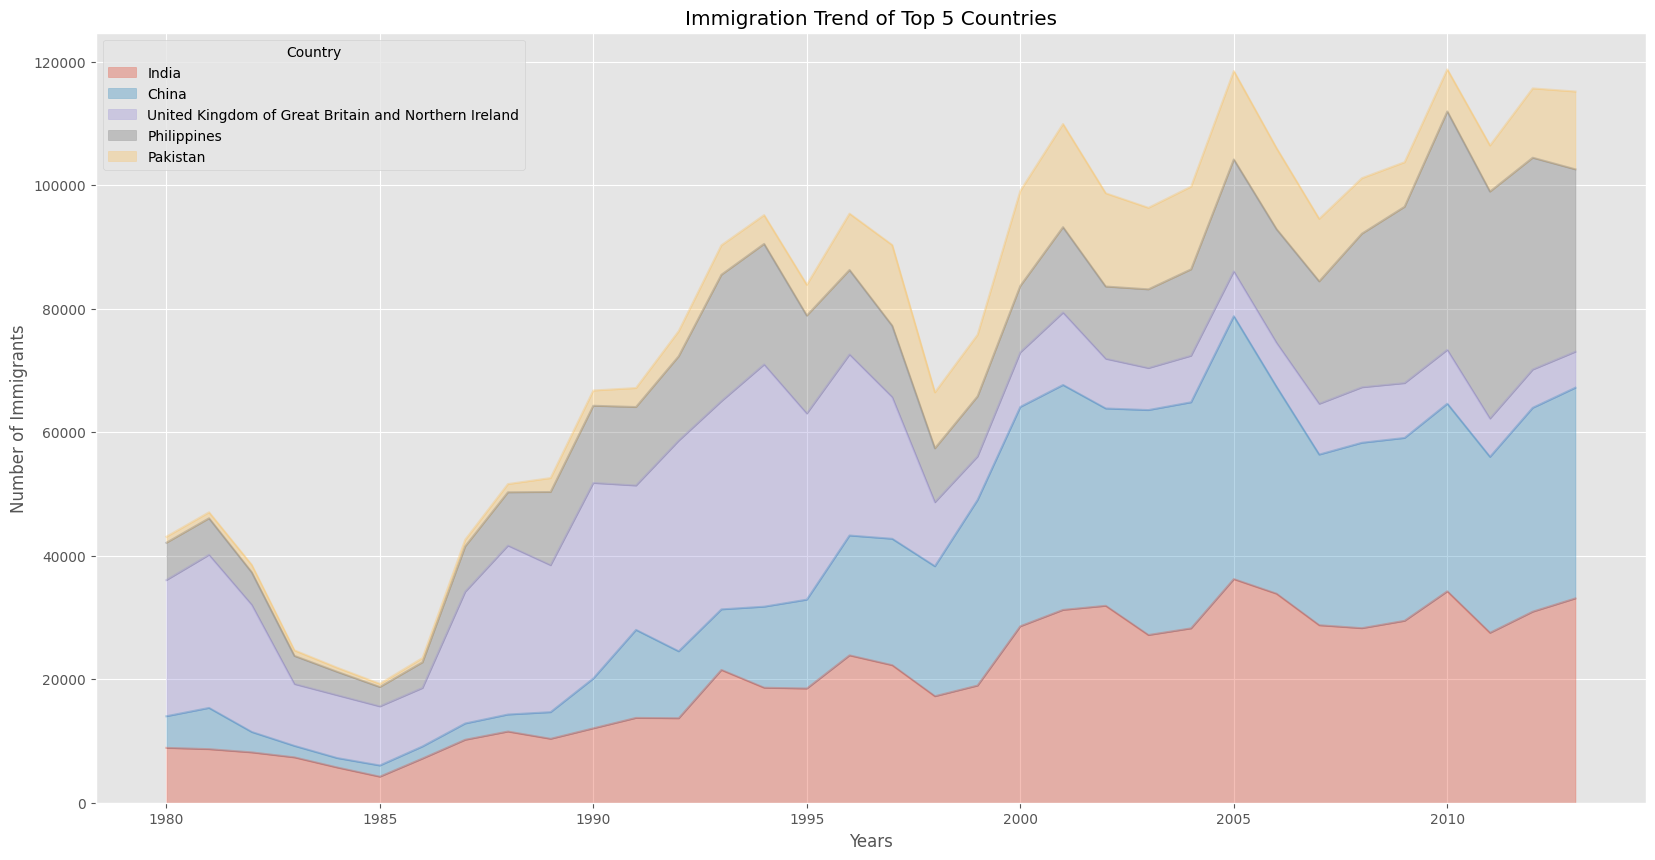

In [19]:
# option 2: preferred option with more flexibility
ax = df_top5.plot(kind='area', alpha=0.35, figsize=(20, 10))

ax.set_title('Immigration Trend of Top 5 Countries')
ax.set_ylabel('Number of Immigrants')
ax.set_xlabel('Years')

**Câu hỏi**: Hãy dùng lớp scripting để tạo một biểu đồ vùng xếp chồng của 5 quốc gia đóng góp ít nhất vào lượng nhập cư vào Canada **từ** năm 1980 đến 2013. Sử dụng giá trị độ trong suốt là 0.45.

In [21]:
### type your answer here

df_can.sort_values(['Total'], ascending=True, axis=0, inplace=True)

# get the top 5 entries
df_top5_least = df_can.head()

# transpose the dataframe
df_top5_least = df_top5_least[years].transpose()

df_top5_least.head()


Country,Palau,Marshall Islands,Western Sahara,San Marino,New Caledonia
1980,0,0,0,1,0
1981,0,0,0,0,0
1982,0,0,0,0,0
1983,0,0,0,0,0
1984,0,0,0,0,0


<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">tail()</code> — dữ liệu đã được sắp xếp giảm dần theo `Total`, nên các quốc gia đóng góp ít nhất nằm ở cuối bảng.
- <code style="color:red">transpose()</code> — để năm là index, quốc gia là cột.
- <code style="color:red">index.map()</code> — đổi index sang số nguyên.
- <code style="color:red">plot()</code> — `kind='area'` kèm các tham số `alpha` và `figsize`.
- <code style="color:red">plt.title()</code> — đặt tiêu đề cho biểu đồ.
- <code style="color:red">plt.xlabel() / plt.ylabel()</code> — gán nhãn cho trục x và trục y.
- <code style="color:red">plt.show()</code> — hiển thị biểu đồ.

> **Mẹo:** Dùng các hàm `plt.` (lớp scripting) theo đúng yêu cầu của câu hỏi.

</details>

Text(0.5, 0, 'Years')

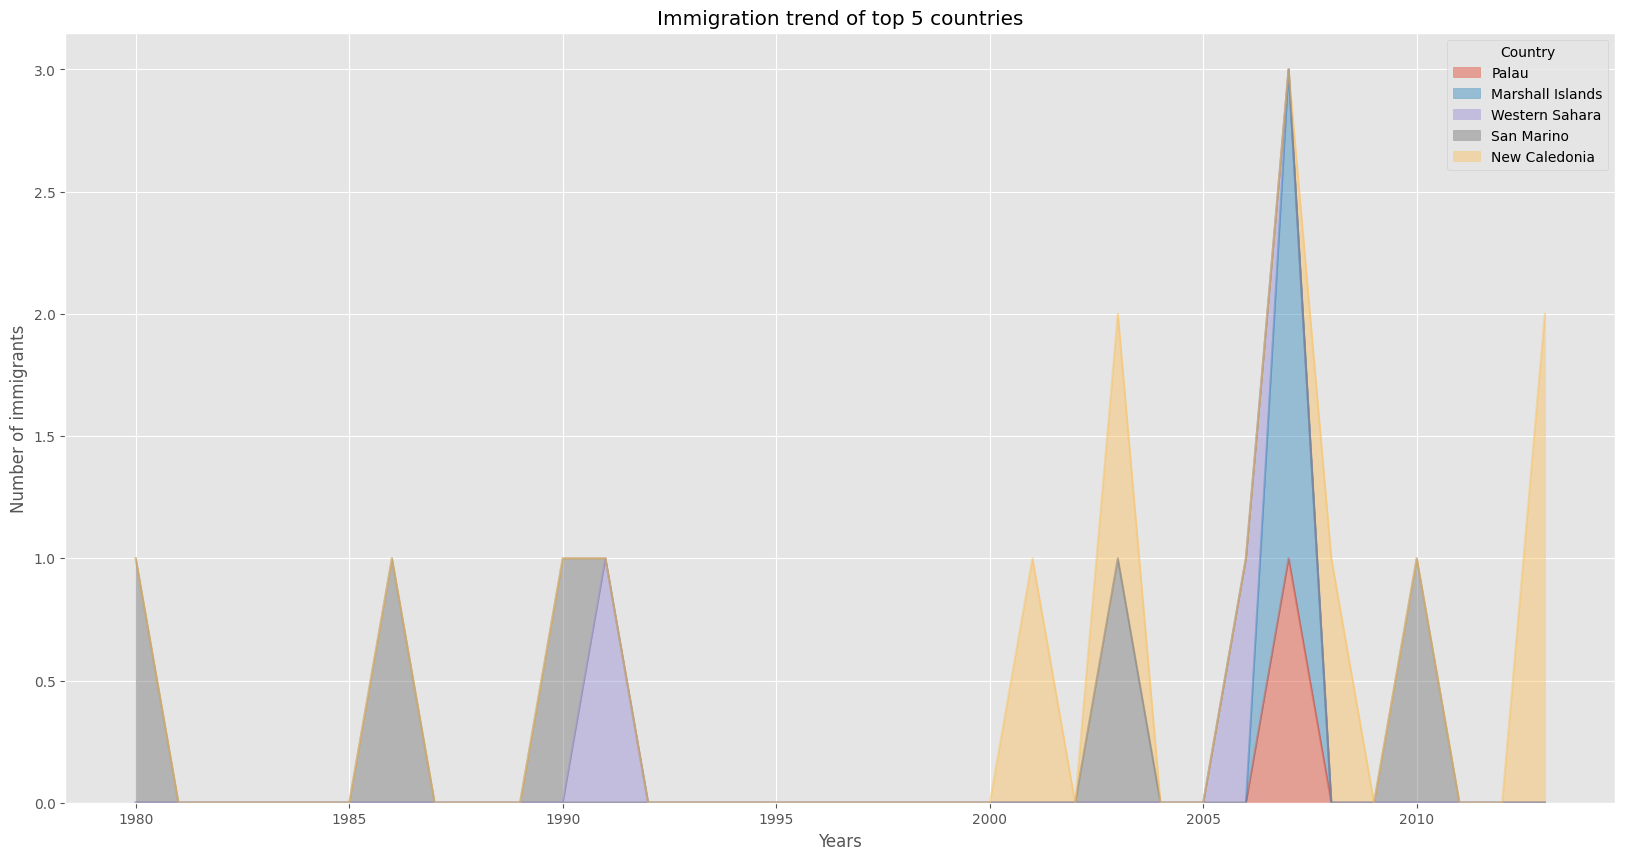

In [25]:
### type your answer here

df_top5_least.plot(kind='area', alpha=0.45, figsize=(20, 10)) 
plt.title('Immigration trend of top 5 countries')
plt.ylabel('Number of immigrants')
plt.xlabel('Years')



**Câu hỏi**: Hãy dùng lớp artist để tạo một biểu đồ vùng không xếp chồng của 5 quốc gia đóng góp ít nhất vào lượng nhập cư vào Canada **từ** năm 1980 đến 2013. Sử dụng giá trị độ trong suốt là 0.55.

<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">tail()</code> — lấy các quốc gia đóng góp ít nhất.
- <code style="color:red">transpose()</code> — hoán đổi dòng/cột.
- <code style="color:red">index.map()</code> — đổi index sang số nguyên.
- <code style="color:red">plot()</code> — `kind='area'`, thêm `alpha` và `stacked` (để biểu đồ không xếp chồng); hãy **lưu kết quả trả về** vào một biến.
- <code style="color:red">ax.set_title() / ax.set_xlabel() / ax.set_ylabel()</code> — đặt tiêu đề và nhãn trục trên đối tượng `Axes` (lớp Artist).

> **Mẹo:** Với lớp Artist, thêm tiền tố `set_` vào các hàm tương ứng của `plt`.

</details>

Text(0.5, 0, 'Years')

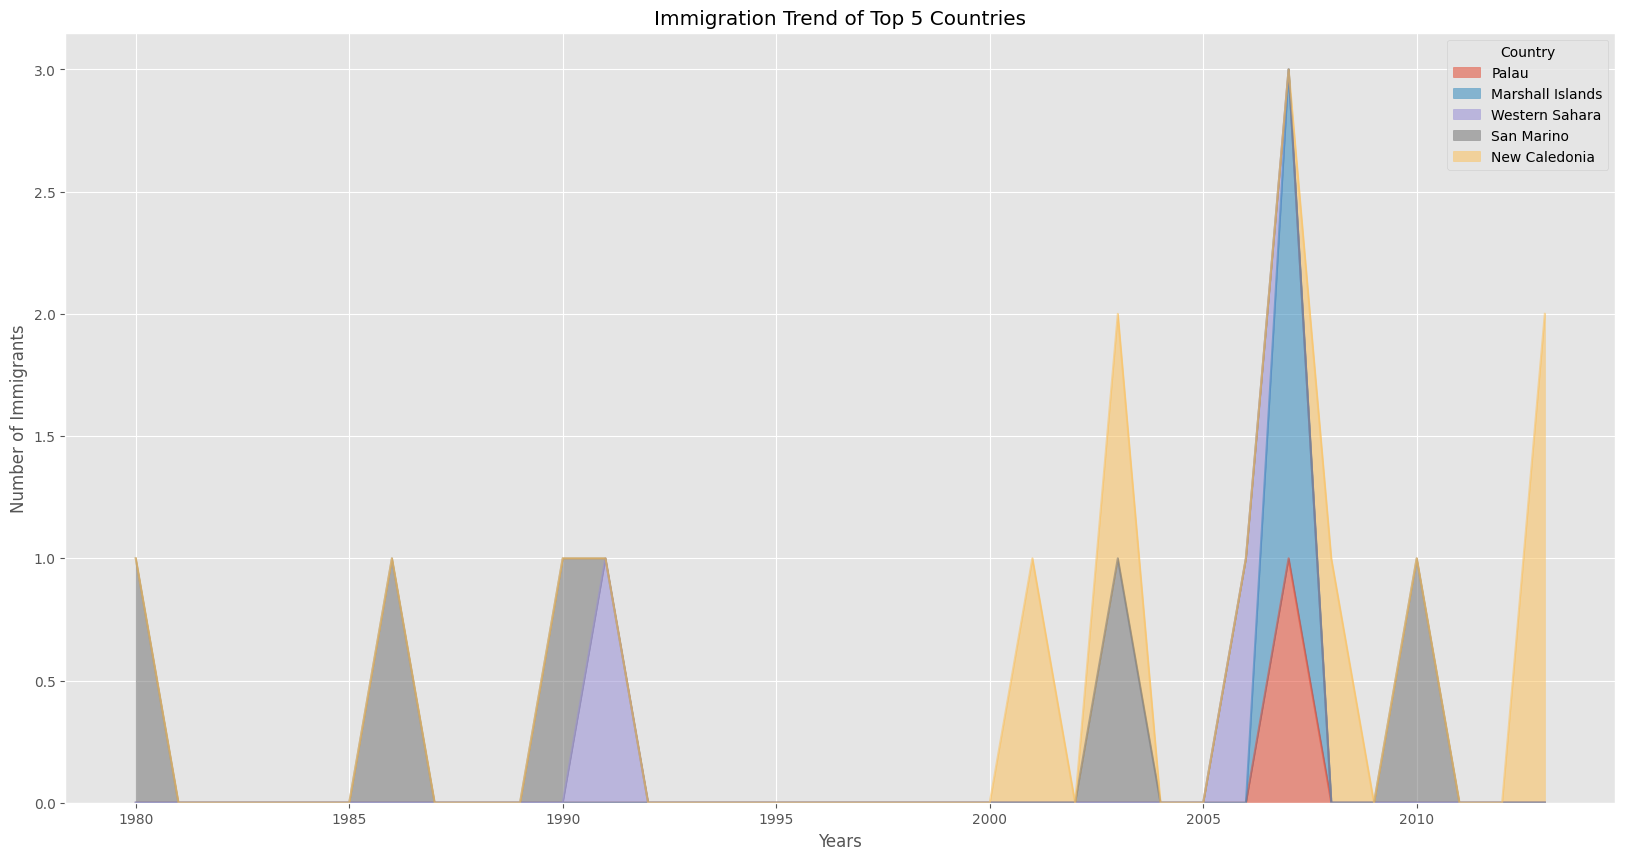

In [26]:
# option 2: preferred option with more flexibility
ax = df_top5_least.plot(kind='area', alpha=0.55, figsize=(20, 10))

ax.set_title('Immigration Trend of Top 5 Countries')
ax.set_ylabel('Number of Immigrants')
ax.set_xlabel('Years')

# Histogram<a id="8"></a>

Histogram là một cách biểu diễn phân phối *tần suất* (frequency) của một bộ dữ liệu dạng số. Cách hoạt động của nó là chia trục x thành các *bin*, gán mỗi điểm dữ liệu trong bộ dữ liệu vào một bin, rồi đếm số điểm dữ liệu được gán vào mỗi bin. Vì vậy, trục y là tần suất hay số điểm dữ liệu trong mỗi bin. Lưu ý rằng chúng ta có thể thay đổi kích thước bin và thường cần điều chỉnh nó để phân phối được hiển thị đẹp mắt.

**Câu hỏi:** Phân phối tần suất của số lượng (dân số) người nhập cư mới từ các quốc gia khác nhau vào Canada trong năm 2013 như thế nào?

Trước khi tiến hành tạo biểu đồ histogram, trước tiên hãy xem xét dữ liệu được chia thành các khoảng. Để làm điều này, chúng ta sẽ dùng phương thức `histrogram` của **Numpy** để lấy các khoảng bin và số đếm tần suất như sau:

In [27]:
# let's quickly view the 2013 data
df_can['2013'].head()

,2013
Country,
Palau,0
Marshall Islands,0
Western Sahara,0
San Marino,0
New Caledonia,2


In [28]:
# np.histogram returns 2 values
count, bin_edges = np.histogram(df_can['2013'])

print(count) # frequency count
print(bin_edges) # bin ranges, default = 10 bins

[178  11   1   2   0   0   0   0   1   2]
[    0.   3412.9  6825.8 10238.7 13651.6 17064.5 20477.4 23890.3 27303.2
 30716.1 34129. ]


Mặc định, phương thức `histrogram` chia bộ dữ liệu thành 10 bin. Hình bên dưới tóm tắt các khoảng bin và phân phối tần suất của lượng nhập cư năm 2013. Chúng ta có thể thấy rằng trong năm 2013:
* 178 quốc gia đóng góp từ 0 đến 3412.9 người nhập cư 
* 11 quốc gia đóng góp từ 3412.9 đến 6825.8 người nhập cư
* 1 quốc gia đóng góp từ 6285.8 đến 10238.7 người nhập cư, và cứ tiếp tục như vậy..

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%202/images/Mod2Fig1-Histogram.jpg" align="center" width="800">

Chúng ta có thể dễ dàng vẽ phân phối này bằng cách truyền `kind=hist` vào `plot()`.

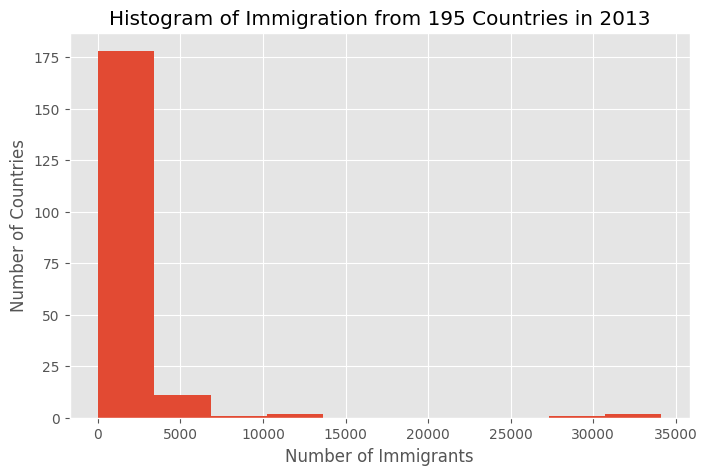

In [29]:
df_can['2013'].plot(kind='hist', figsize=(8, 5))

# add a title to the histogram
plt.title('Histogram of Immigration from 195 Countries in 2013')
# add y-label
plt.ylabel('Number of Countries')
# add x-label
plt.xlabel('Number of Immigrants')

plt.show()

Trong biểu đồ trên, trục x biểu diễn khoảng dân số người nhập cư theo các khoảng 3412.9. Trục y biểu diễn số quốc gia đã đóng góp vào lượng dân số nêu trên. 

Hãy lưu ý rằng các nhãn trục x không khớp với kích thước bin. Điều này có thể được khắc phục bằng cách truyền từ khóa `xticks` chứa danh sách các kích thước bin, như sau:

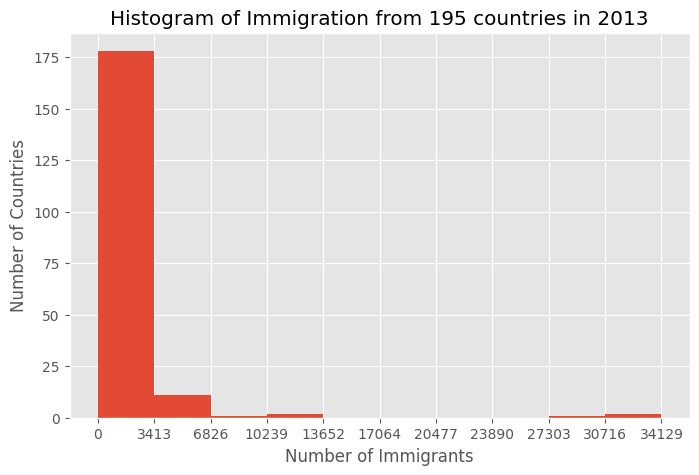

In [30]:
# 'bin_edges' is a list of bin intervals
count, bin_edges = np.histogram(df_can['2013'])

df_can['2013'].plot(kind='hist', figsize=(8, 5), xticks=bin_edges)

plt.title('Histogram of Immigration from 195 countries in 2013') # add a title to the histogram
plt.ylabel('Number of Countries') # add y-label
plt.xlabel('Number of Immigrants') # add x-label

plt.show()

*Lưu ý thêm:* Chúng ta có thể dùng `df_can['2013'].plot.hist()` thay thế. Thực tế, trong suốt bài học này, việc dùng `some_data.plot(kind='type_plot', ...)` tương đương với `some_data.plot.type_plot(...)`. Nghĩa là, truyền loại biểu đồ dưới dạng đối số hay dưới dạng phương thức đều cho kết quả như nhau. 

Xem tài liệu của *pandas* để biết thêm thông tin  http://pandas.pydata.org/pandas-docs/stable/generated/pandas.Series.plot.html.

Chúng ta cũng có thể vẽ nhiều histogram trên cùng một biểu đồ. Ví dụ, hãy thử trả lời câu hỏi sau bằng histogram.

**Câu hỏi**: Phân phối nhập cư của Đan Mạch (Denmark), Na Uy (Norway) và Thụy Điển (Sweden) trong các năm 1980 - 2013 như thế nào?

In [31]:
# let's quickly view the dataset 
df_can.loc[['Denmark', 'Norway', 'Sweden'], years]

,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
Country,,,,,,,,,,,,,,,,,,,,,
Denmark,272,293,299,106,93,73,93,109,129,129,...,89,62,101,97,108,81,92,93,94,81
Norway,116,77,106,51,31,54,56,80,73,76,...,73,57,53,73,66,75,46,49,53,59
Sweden,281,308,222,176,128,158,187,198,171,182,...,129,205,139,193,165,167,159,134,140,140


<Axes: ylabel='Frequency'>

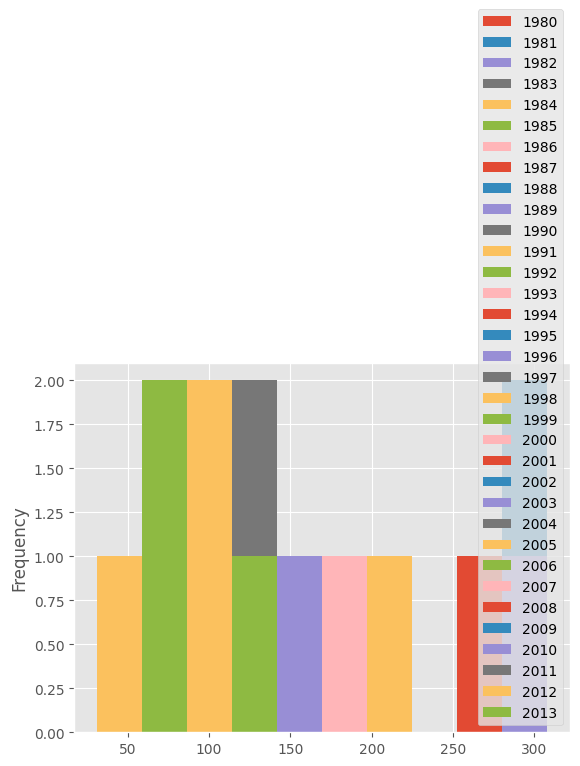

In [32]:
# generate histogram
df_can.loc[['Denmark', 'Norway', 'Sweden'], years].plot.hist()

Trông chưa đúng! 

Đừng lo, bạn sẽ thường gặp những tình huống như thế này khi tạo biểu đồ. Giải pháp thường nằm ở cách bộ dữ liệu bên dưới được cấu trúc.

Thay vì vẽ phân phối tần suất dân số của 3 quốc gia, *pandas* lại vẽ phân phối tần suất dân số theo các `years`.

Điều này có thể được khắc phục dễ dàng bằng cách trước tiên chuyển vị (transpose) bộ dữ liệu, sau đó vẽ biểu đồ như bên dưới.


In [33]:
# transpose dataframe
df_t = df_can.loc[['Denmark', 'Norway', 'Sweden'], years].transpose()
df_t.head()

Country,Denmark,Norway,Sweden
1980,272,116,281
1981,293,77,308
1982,299,106,222
1983,106,51,176
1984,93,31,128


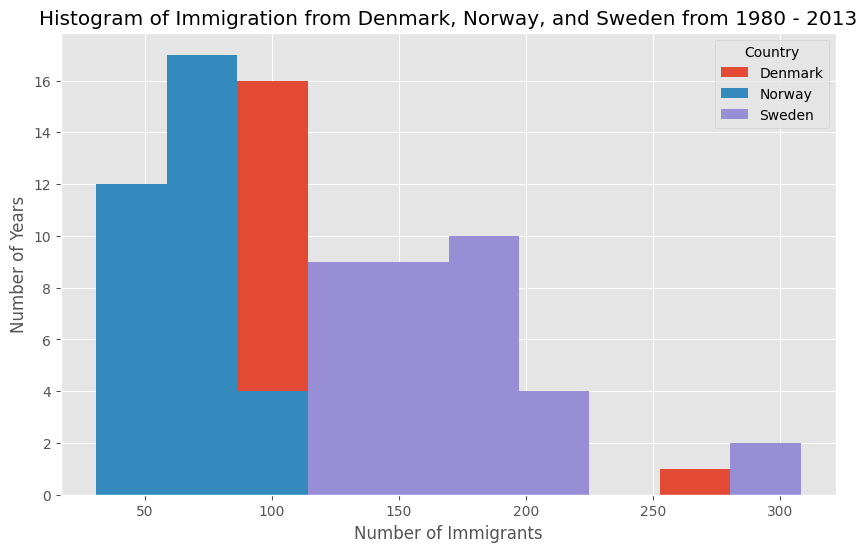

In [34]:
# generate histogram
df_t.plot(kind='hist', figsize=(10, 6))

plt.title('Histogram of Immigration from Denmark, Norway, and Sweden from 1980 - 2013')
plt.ylabel('Number of Years')
plt.xlabel('Number of Immigrants')

plt.show()

Hãy thực hiện một vài chỉnh sửa để cải thiện tác động và tính thẩm mỹ của biểu đồ trước:
* tăng kích thước bin lên 15 bằng cách truyền tham số `bins`;
* đặt độ trong suốt là 60% bằng cách truyền tham số `alpha`;
* gán nhãn cho trục x bằng cách truyền tham số `x-label`;
* thay đổi màu sắc của các biểu đồ bằng cách truyền tham số `color`.

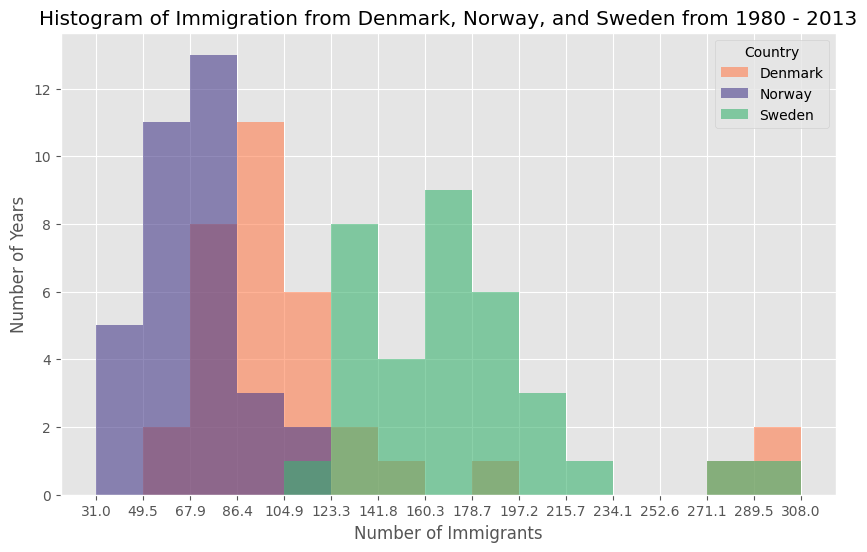

In [44]:
# let's get the x-tick values
count, bin_edges = np.histogram(df_t, 15)

# un-stacked histogram
df_t.plot(kind ='hist', 
          figsize=(10, 6),
          bins=15,
          alpha=0.6,
          xticks=bin_edges,
          color=['coral', 'darkslateblue', 'mediumseagreen']
         )

plt.title('Histogram of Immigration from Denmark, Norway, and Sweden from 1980 - 2013')
plt.ylabel('Number of Years')
plt.xlabel('Number of Immigrants')

plt.show()

Mẹo:
Để xem danh sách đầy đủ các màu có sẵn trong Matplotlib, hãy chạy đoạn code sau trong python shell của bạn:
```python
import matplotlib
for name, hex in matplotlib.colors.cnames.items():
    print(name, hex)
```

Nếu không muốn các biểu đồ chồng lên nhau, chúng ta có thể xếp chồng chúng bằng tham số `stacked`. Hãy cũng điều chỉnh giá trị nhỏ nhất và lớn nhất của nhãn trục x để loại bỏ khoảng trống thừa ở các cạnh của biểu đồ. Chúng ta có thể truyền một tuple (min,max) bằng tham số `xlim`, như bên dưới.

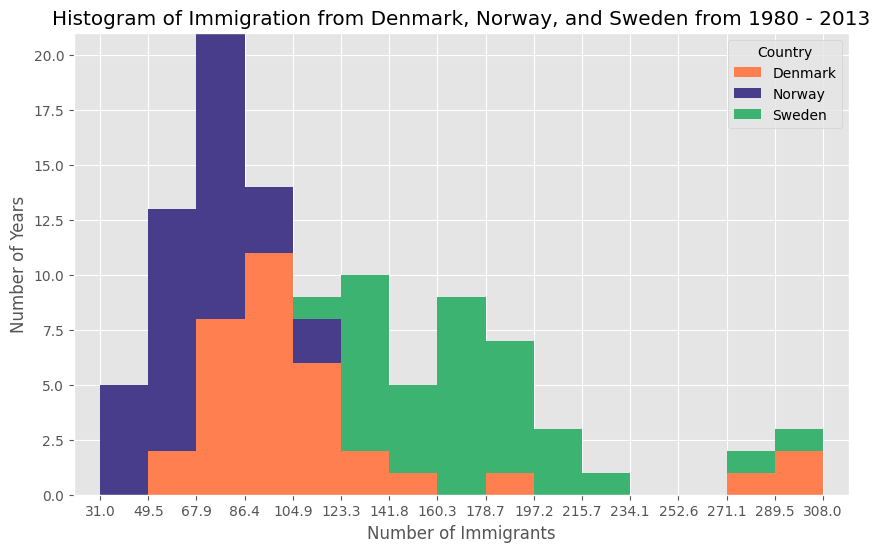

In [36]:
count, bin_edges = np.histogram(df_t, 15)
xmin = bin_edges[0] - 10   #  first bin value is 31.0, adding buffer of 10 for aesthetic purposes 
xmax = bin_edges[-1] + 10  #  last bin value is 308.0, adding buffer of 10 for aesthetic purposes

# stacked Histogram
df_t.plot(kind='hist',
          figsize=(10, 6), 
          bins=15,
          xticks=bin_edges,
          color=['coral', 'darkslateblue', 'mediumseagreen'],
          stacked=True,
          xlim=(xmin, xmax)
         )

plt.title('Histogram of Immigration from Denmark, Norway, and Sweden from 1980 - 2013')
plt.ylabel('Number of Years')
plt.xlabel('Number of Immigrants') 

plt.show()

**Câu hỏi**: Hãy dùng lớp scripting để hiển thị phân phối nhập cư của Hy Lạp (Greece), Albania và Bulgaria trong các năm 1980 - 2013. Sử dụng biểu đồ chồng lấp (overlapping) với 15 bin và giá trị độ trong suốt là 0.35.

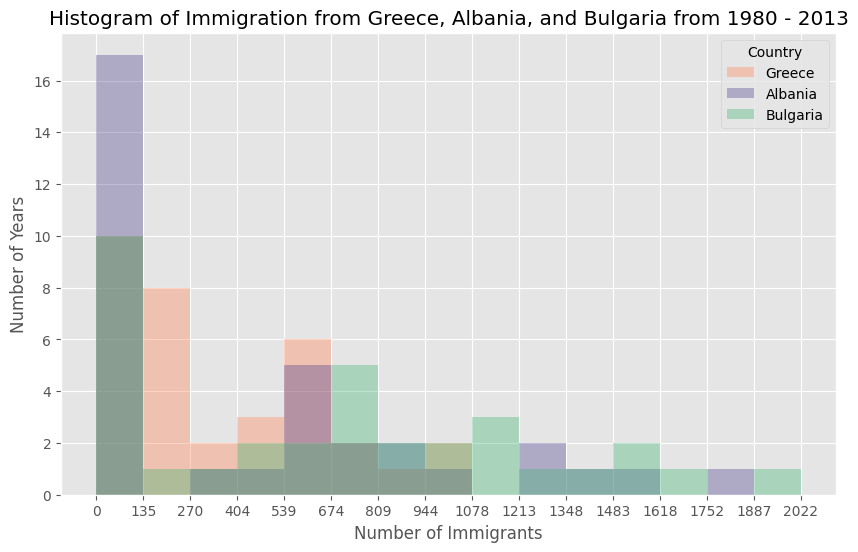

In [45]:
### type your answer here

df_gab = df_can.loc[['Greece','Albania','Bulgaria'],years].transpose()

# let's get the x-tick values
count, bin_edges = np.histogram(df_gab, 15)

# un-stacked histogram
df_gab.plot(kind ='hist', 
          figsize=(10, 6),
          bins=15,
          alpha=0.35,
          xticks=bin_edges,
          color=['coral', 'darkslateblue', 'mediumseagreen']
         )

plt.title('Histogram of Immigration from Greece, Albania, and Bulgaria from 1980 - 2013')
plt.ylabel('Number of Years')
plt.xlabel('Number of Immigrants')

plt.show()



<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">loc[]</code> — chọn 3 quốc gia theo tên và các cột năm.
- <code style="color:red">transpose()</code> — để mỗi quốc gia là một cột.
- <code style="color:red">np.histogram()</code> — lấy `bin_edges` với số bin cho trước để truyền vào `xticks`.
- <code style="color:red">plot()</code> — `kind='hist'` cùng các tham số `bins`, `alpha`, `xticks`, `color`, `figsize`.
- <code style="color:red">plt.title()</code> — đặt tiêu đề cho biểu đồ.
- <code style="color:red">plt.xlabel() / plt.ylabel()</code> — gán nhãn cho trục x và trục y.
- <code style="color:red">plt.show()</code> — hiển thị biểu đồ.

</details>

# Biểu đồ cột (Bar Charts) (Dataframe) <a id="10"></a>

Biểu đồ cột (bar plot) là một cách biểu diễn dữ liệu trong đó *độ dài* của các cột thể hiện độ lớn/kích thước của đặc trưng/biến. Biểu đồ cột thường biểu diễn các biến số và biến phân loại (categorical) được nhóm theo khoảng. 

Để tạo biểu đồ cột, chúng ta có thể truyền một trong hai đối số qua tham số `kind` trong `plot()`:

* `kind=bar` tạo biểu đồ cột *dọc* (vertical)
* `kind=barh` tạo biểu đồ cột *ngang* (horizontal)

**Biểu đồ cột dọc (Vertical bar plot)**

Trong biểu đồ cột dọc, trục x được dùng để gán nhãn, và độ dài của các cột trên trục y tương ứng với độ lớn của biến được đo. Biểu đồ cột dọc đặc biệt hữu ích khi phân tích dữ liệu chuỗi thời gian (time series). Một nhược điểm là chúng thiếu không gian để ghi chú văn bản ở chân mỗi cột.

**Hãy bắt đầu bằng việc phân tích tác động của cuộc khủng hoảng tài chính Iceland:**

Cuộc khủng hoảng tài chính Iceland giai đoạn 2008 - 2011 là một sự kiện kinh tế và chính trị lớn tại Iceland. So với quy mô nền kinh tế, sự sụp đổ mang tính hệ thống của ngành ngân hàng Iceland là lớn nhất mà bất kỳ quốc gia nào từng trải qua trong lịch sử kinh tế. Cuộc khủng hoảng dẫn đến một cuộc suy thoái kinh tế nghiêm trọng trong giai đoạn 2008 - 2011 và bất ổn chính trị đáng kể.

**Câu hỏi:** Hãy so sánh số lượng người nhập cư Iceland (country = 'Iceland') vào Canada từ năm 1980 đến 2013. 

In [46]:
# step 1: get the data
df_iceland = df_can.loc['Iceland', years]
df_iceland.head()

,Iceland
1980,17
1981,33
1982,10
1983,9
1984,13


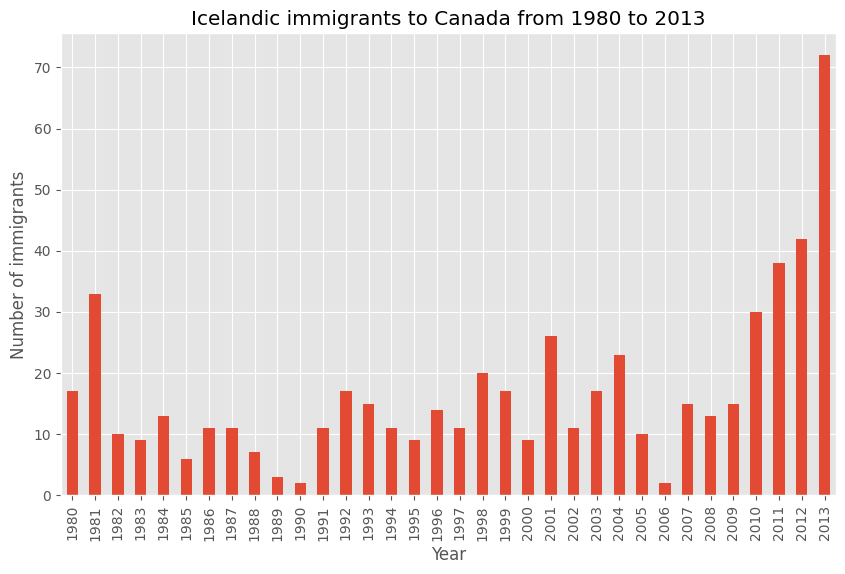

In [47]:
# step 2: plot data
df_iceland.plot(kind='bar', figsize=(10, 6))

plt.xlabel('Year') # add to x-label to the plot
plt.ylabel('Number of immigrants') # add y-label to the plot
plt.title('Icelandic immigrants to Canada from 1980 to 2013') # add title to the plot

plt.show()

Biểu đồ cột ở trên cho thấy tổng số người nhập cư được chia theo từng năm. Chúng ta có thể thấy rõ tác động của cuộc khủng hoảng tài chính; số người nhập cư vào Canada bắt đầu tăng nhanh sau năm 2008. 

Hãy chú thích (annotate) điều này trên biểu đồ bằng phương thức `annotate` của **lớp scripting** hay **giao diện pyplot**. Chúng ta sẽ truyền vào các tham số sau:
- `s`: str, nội dung văn bản của chú thích.
- `xy`: Tuple chỉ định điểm (x,y) cần chú thích (trong trường hợp này là điểm cuối của mũi tên).
- `xytext`: Tuple chỉ định điểm (x,y) để đặt văn bản (trong trường hợp này là điểm bắt đầu của mũi tên).
- `xycoords`: Hệ tọa độ mà xy được cung cấp - 'data' sử dụng hệ tọa độ của đối tượng đang được chú thích (mặc định).
- `arrowprops`: Nhận một dictionary các thuộc tính để vẽ mũi tên:
    - `arrowstyle`: Chỉ định kiểu mũi tên, `'->'` là mũi tên tiêu chuẩn.
    - `connectionstyle`: Chỉ định kiểu kết nối. `arc3` là một đường thẳng.
    - `color`: Chỉ định màu của mũi tên.
    - `lw`: Chỉ định độ rộng của đường.

Tôi khuyến khích bạn đọc tài liệu Matplotlib để biết thêm chi tiết về chú thích: 
http://matplotlib.orsg/api/pyplot_api.html#matplotlib.pyplot.annotate.

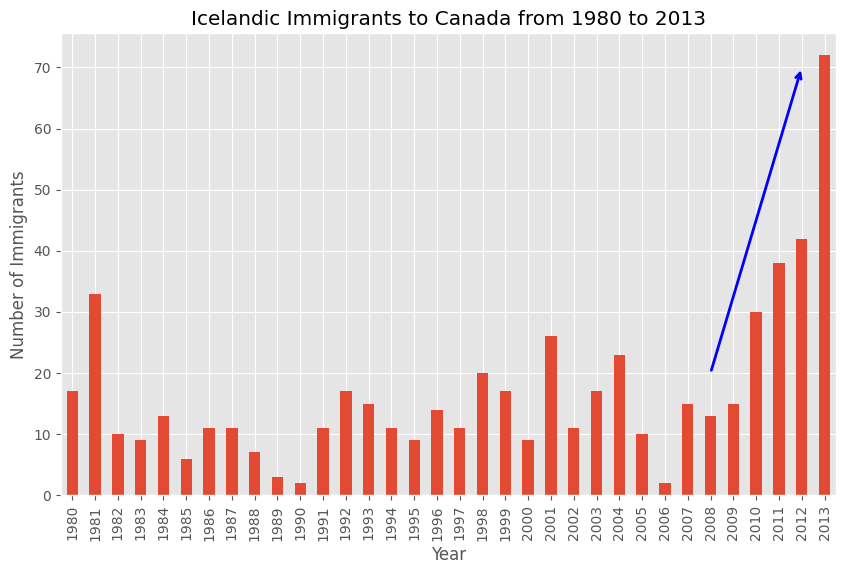

In [48]:
df_iceland.plot(kind='bar', figsize=(10, 6), rot=90)  # rotate the xticks(labelled points on x-axis) by 90 degrees

plt.xlabel('Year')
plt.ylabel('Number of Immigrants')
plt.title('Icelandic Immigrants to Canada from 1980 to 2013')

# Annotate arrow
plt.annotate('',  # s: str. Will leave it blank for no text
             xy=(32, 70),  # place head of the arrow at point (year 2012 , pop 70)
             xytext=(28, 20),  # place base of the arrow at point (year 2008 , pop 20)
             xycoords='data',  # will use the coordinate system of the object being annotated
             arrowprops=dict(arrowstyle='->', connectionstyle='arc3', color='blue', lw=2)
             )

plt.show()

Hãy cũng chú thích một đoạn văn bản đặt phía trên mũi tên.  Chúng ta sẽ truyền thêm các tham số sau:
- `rotation`: góc xoay của văn bản tính bằng độ (ngược chiều kim đồng hồ)
- `va`: căn chỉnh theo chiều dọc của văn bản [‘center’ | ‘top’ | ‘bottom’ | ‘baseline’]
- `ha`: căn chỉnh theo chiều ngang của văn bản [‘center’ | ‘right’ | ‘left’]

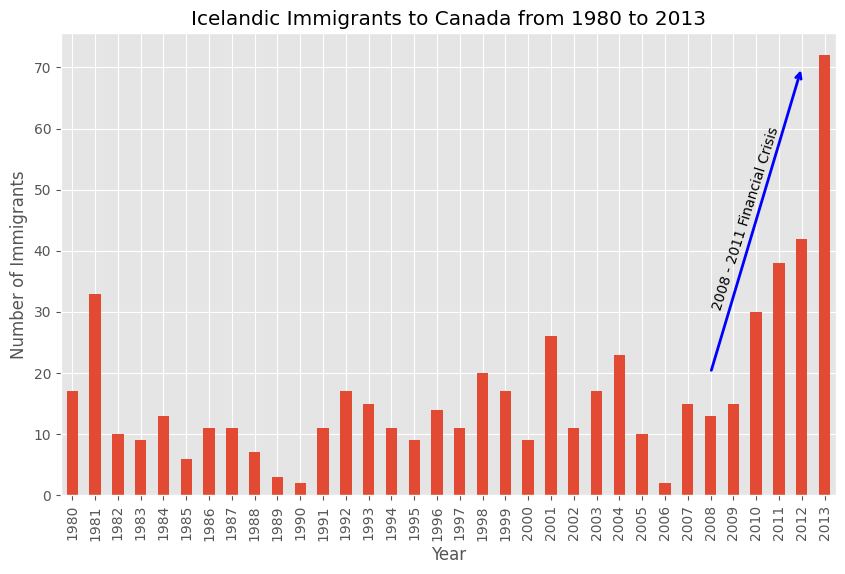

In [49]:
df_iceland.plot(kind='bar', figsize=(10, 6), rot=90)

plt.xlabel('Year')
plt.ylabel('Number of Immigrants')
plt.title('Icelandic Immigrants to Canada from 1980 to 2013')

# Annotate arrow
plt.annotate('',  # s: str. will leave it blank for no text
             xy=(32, 70),  # place head of the arrow at point (year 2012 , pop 70)
             xytext=(28, 20),  # place base of the arrow at point (year 2008 , pop 20)
             xycoords='data',  # will use the coordinate system of the object being annotated
             arrowprops=dict(arrowstyle='->', connectionstyle='arc3', color='blue', lw=2)
             )

# Annotate Text
plt.annotate('2008 - 2011 Financial Crisis',  # text to display
             xy=(28, 30),  # start the text at at point (year 2008 , pop 30)
             rotation=72.5,  # based on trial and error to match the arrow
             va='bottom',  # want the text to be vertically 'bottom' aligned
             ha='left',  # want the text to be horizontally 'left' algned.
             )

plt.show()

**Biểu đồ cột ngang (Horizontal Bar Plot)**

Đôi khi việc biểu diễn dữ liệu theo chiều ngang thực tế hơn, đặc biệt nếu bạn cần thêm chỗ để gán nhãn cho các cột. Trong biểu đồ cột ngang, trục y được dùng để gán nhãn, và độ dài của các cột trên trục x tương ứng với độ lớn của biến được đo. Như bạn sẽ thấy, có nhiều chỗ hơn trên trục y để gán nhãn cho các biến phân loại.


**Câu hỏi:** Sử dụng lớp scripting và bộ dữ liệu `df_can`, hãy tạo một biểu đồ cột *ngang* thể hiện *tổng* số người nhập cư vào Canada từ 15 quốc gia hàng đầu, trong giai đoạn 1980 - 2013. Gán nhãn cho mỗi quốc gia với tổng số người nhập cư.

Bước 1: Lấy dữ liệu của 15 quốc gia hàng đầu.

In [ ]:
### type your answer here

df_can.sort_values(by='Total', ascending=True, inplace=True)
df_top15 = df_can['Total'].tail(15)
df_top15

,Total
Country,
Romania,93585
Viet Nam,97146
Jamaica,106431
France,109091
Lebanon,115359
Poland,139241
Republic of Korea,142581
Sri Lanka,148358
Iran (Islamic Republic of),175923


<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">sort_values()</code> — sắp xếp `df_can` theo `Total` (chú ý `ascending`, `inplace`).
- <code style="color:red">tail()</code> — lấy 15 quốc gia đứng cuối sau khi sắp xếp; thử chọn riêng cột `Total` trước.

</details>

Bước 2: Vẽ biểu đồ:
   1. Dùng `kind='barh'` để tạo biểu đồ cột với các cột nằm ngang.
   2. Hãy chọn kích thước biểu đồ phù hợp, gán nhãn cho các trục và đặt tiêu đề cho biểu đồ.
   3. Lặp qua các quốc gia và chú thích dân số người nhập cư bằng hàm annotate của giao diện scripting.

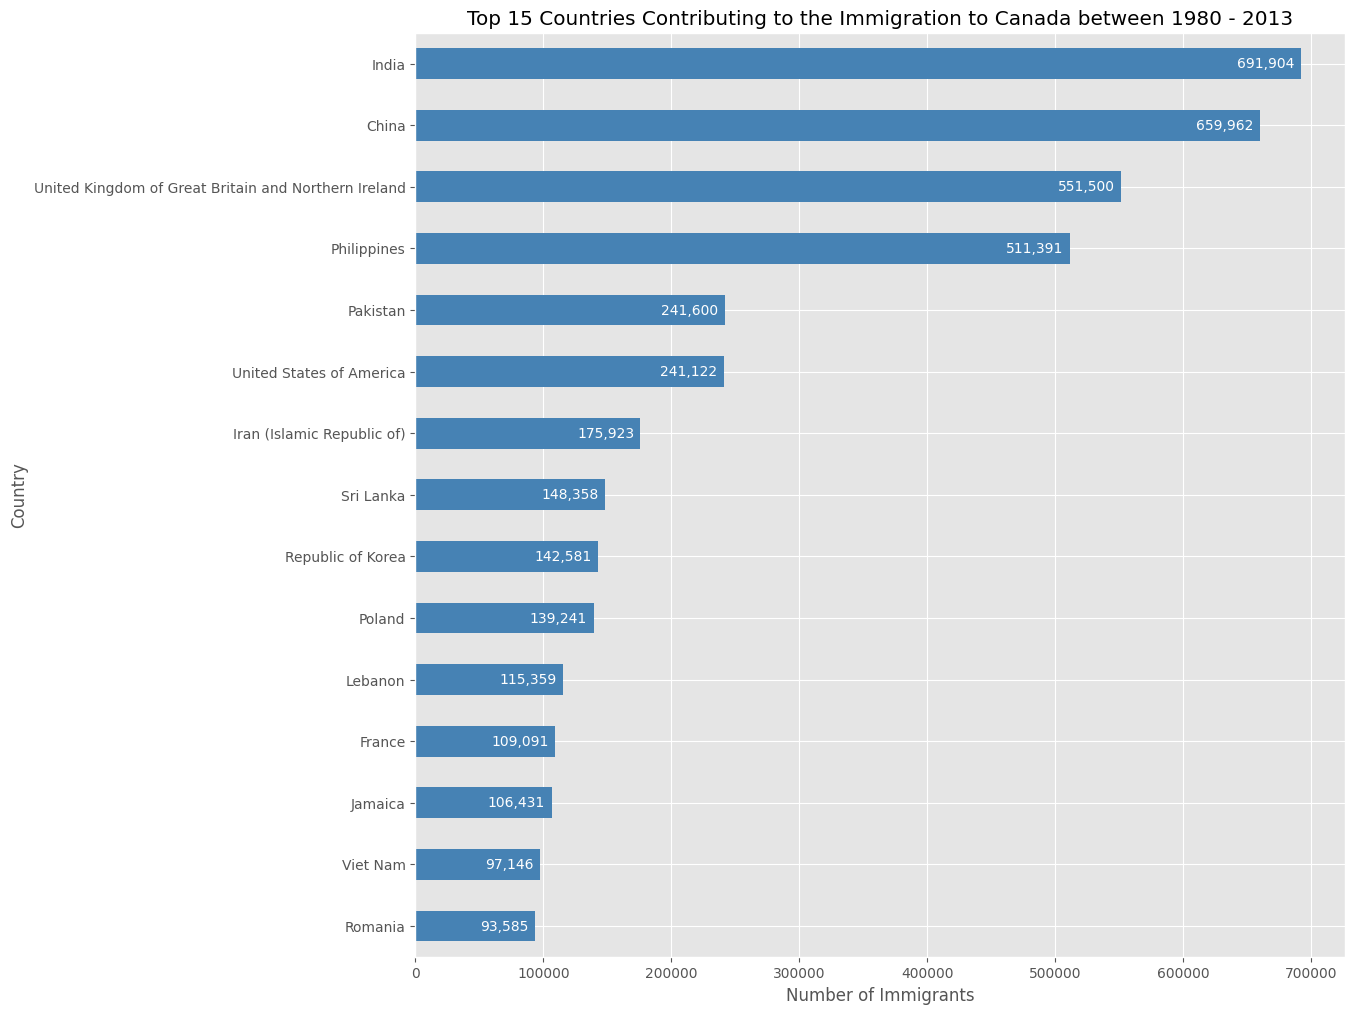

In [ ]:
### type your answer here

df_top15.plot(kind='barh', figsize=(12, 12), color='steelblue')

plt.xlabel('Number of Immigrants')
plt.title('Top 15 Countries Contributing to the Immigration to Canada between 1980 - 2013')

for index, value in enumerate(df_top15): 
    label = format(int(value), ',')
    plt.annotate(label,
                 # Vị trí đặt label tổng số dân nhập cư 
                 xy=(value - 5000, index),
                 ha='right', 
                 va='center',  
                 color='white')

plt.show()

<details><summary>Nhấn vào đây để xem gợi ý về các hàm cần dùng</summary>

### 💡 Gợi ý

Bạn có thể cân nhắc các hàm sau:

- <code style="color:red">plot()</code> — `kind='barh'` cùng `figsize` và `color`.
- <code style="color:red">enumerate()</code> — duyệt qua từng quốc gia kèm vị trí của nó trên trục y.
- <code style="color:red">format()</code> — định dạng số kèm dấu phẩy ngăn cách hàng nghìn.
- <code style="color:red">plt.annotate()</code> — ghi nhãn số liệu cạnh mỗi cột; tham số `xy` là vị trí đặt nhãn.
- <code style="color:red">plt.xlabel() / plt.title()</code> — nhãn trục và tiêu đề.
- <code style="color:red">plt.show()</code> — hiển thị biểu đồ.

> **Mẹo:** Đặt lệnh `plt.annotate()` **bên trong** vòng lặp để mọi quốc gia đều có nhãn.

</details>

### Cảm ơn bạn đã hoàn thành bài thực hành này!


## Tác giả

<a href="https://www.linkedin.com/in/aklson/" target="_blank">Alex Aklson</a>


### Những người đóng góp khác
[Jay Rajasekharan](https://www.linkedin.com/in/jayrajasekharan),
[Ehsan M. Kermani](https://www.linkedin.com/in/ehsanmkermani),
[Slobodan Markovic](https://www.linkedin.com/in/slobodan-markovic),
[Weiqing Wang](https://www.linkedin.com/in/weiqing-wang-641640133/).


## Nhật ký thay đổi


|  Ngày (YYYY-MM-DD) |  Phiên bản | Người thay đổi  |  Mô tả thay đổi |
|---|---|---|---|
| 2021-05-29 | 2.4 | Weiqing Wang | Sửa lỗi chính tả và code smell. |
| 2021-01-20 | 2.3  | Lakshmi Holla  | Thay đổi markdown của ô mục lục (TOC) |
| 2021-01-05 | 2.2  | Lakshmi Holla  | Thay đổi code lời giải cho annotate |
| 2020-11-03  | 2.1  | Lakshmi Holla  |  Thay đổi URL của tệp excel |
| 2020-08-27  | 2.0  | Lavanya  |  Chuyển bài thực hành vào repo khóa học trên GitLab |



## <h3 align="center"> © IBM Corporation 2020. Bảo lưu mọi quyền. <h3/>